In [1]:
print("Hello CodeAlpha!")
print("My First Machine Learning Project")

Hello CodeAlpha!
My First Machine Learning Project


In [2]:
!pip install tensorflow numpy matplotlib scikit-learn

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)


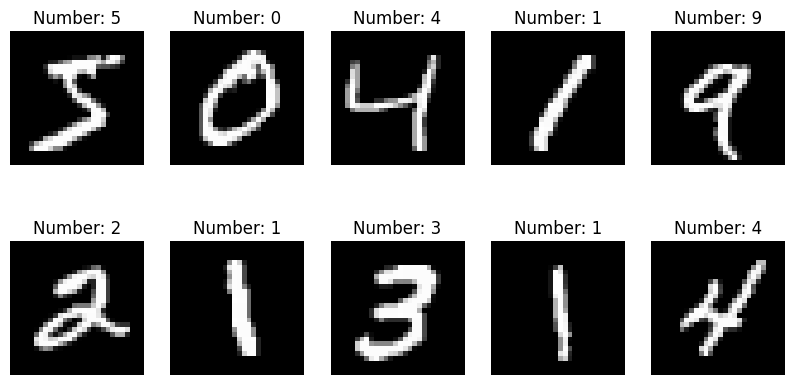

In [4]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Number: {y_train[i]}")
    plt.axis('off')

plt.show()

In [5]:
# Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

# Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Data preprocessing completed!")
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Data preprocessing completed!
Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

# Create CNN Model
model = Sequential([
    Conv2D(32, (3,3), activation='relu',
           input_shape=(28,28,1)),

    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),

    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(10, activation='softmax')
])

# Compile Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Show Model Summary
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 50ms/step - accuracy: 0.9347 - loss: 0.2148 - val_accuracy: 0.9837 - val_loss: 0.0573
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 49ms/step - accuracy: 0.9806 - loss: 0.0635 - val_accuracy: 0.9880 - val_loss: 0.0415
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 51ms/step - accuracy: 0.9864 - loss: 0.0439 - val_accuracy: 0.9912 - val_loss: 0.0323
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 49ms/step - accuracy: 0.9884 - loss: 0.0377 - val_accuracy: 0.9902 - val_loss: 0.0351
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9910 - loss: 0.0292 - val_accuracy: 0.9907 - val_loss: 0.0334


In [8]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test
)

print("Model Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9919 - loss: 0.0259
Model Accuracy: 99.19000267982483 %
Test Loss: 0.02587234415113926


In [11]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Final Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9919 - loss: 0.0259
Final Accuracy: 99.19 %


In [9]:
predictions = model.predict(x_test[:10])

for i in range(10):
    predicted_number = np.argmax(predictions[i])

    print(
        "Actual:", y_test[i],
        "| Predicted:", predicted_number
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Actual: 7 | Predicted: 7
Actual: 2 | Predicted: 2
Actual: 1 | Predicted: 1
Actual: 0 | Predicted: 0
Actual: 4 | Predicted: 4
Actual: 1 | Predicted: 1
Actual: 4 | Predicted: 4
Actual: 9 | Predicted: 9
Actual: 5 | Predicted: 5
Actual: 9 | Predicted: 9


In [10]:
model.save("CodeAlpha_MNIST_Model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!
